In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.dispatch import annual_bill, buy_price, feed_in_price
from src.config import TARIFF

fc = pd.read_csv(ROOT / "results" / "forecasts.csv", index_col=0, parse_dates=True)
spot = fc["price_actual_mwh"]
runs = {n: pd.read_csv(ROOT / "results" / f"run_{n}.csv.gz", index_col=0, parse_dates=True)
        for n in ["A", "B", "C", "C2", "D"]}
n_days = len(fc) / 24
names = {"A": "A  No battery", "B": "B  Simple rule", "C": "C  SVR forecast",
         "C2": "C2 Last-week forecast", "D": "D  Perfect foresight"}

bills = pd.DataFrame({n: annual_bill(r["import_kwh"], r["export_kwh"], spot.values, n_days)
                      for n, r in runs.items()}).T
bills

,import_cost,export_revenue,supply_charge,total
A,832.171158,87.226141,434.8926,1179.837618
B,245.522260,36.954223,434.8926,643.460637
C,228.684861,72.824811,434.8926,590.752650
C2,257.538426,53.406677,434.8926,639.024349
D,230.691445,119.449896,434.8926,546.134148


In [2]:
table = pd.DataFrame({
    "Bill ($)": bills["total"],
    "Saving vs A ($)": bills.loc["A", "total"] - bills["total"],
    "Saving vs B ($)": bills.loc["B", "total"] - bills["total"],
})
table["Saving vs A (%)"] = 100 * table["Saving vs A ($)"] / bills.loc["A", "total"]
table.index = [names[i] for i in table.index]
display(table.round(2))

gain = {k: bills.loc["A", "total"] - bills.loc[k, "total"] for k in runs}
print(f"Forecast error cost (C - D):           ${bills.loc['C','total'] - bills.loc['D','total']:.2f}")
print(f"C captures {100*gain['C']/gain['D']:.1f}% of D's saving; the last-week forecast (C2) captures {100*gain['C2']/gain['D']:.1f}%")
print(f"Value of the SVR over last-week (C2 - C): ${bills.loc['C2','total'] - bills.loc['C','total']:.2f}")
print(f"C beats the simple rule B by:          ${bills.loc['B','total'] - bills.loc['C','total']:.2f}")
print(f"Most any planner could beat B (D):     ${bills.loc['B','total'] - bills.loc['D','total']:.2f}")
print(f"Fixed supply charge nobody can reduce: ${bills.loc['A','supply_charge']:.2f}")

,Bill ($),Saving vs A ($),Saving vs B ($),Saving vs A (%)
A No battery,1179.84,0.00,-536.38,0.00
B Simple rule,643.46,536.38,0.00,45.46
C SVR forecast,590.75,589.08,52.71,49.93
C2 Last-week forecast,639.02,540.81,4.44,45.84
D Perfect foresight,546.13,633.70,97.33,53.71


Forecast error cost (C - D):           $44.62
C captures 93.0% of D's saving; the last-week forecast (C2) captures 85.3%
Value of the SVR over last-week (C2 - C): $48.27
C beats the simple rule B by:          $52.71
Most any planner could beat B (D):     $97.33
Fixed supply charge nobody can reduce: $434.89


In [3]:
buy = pd.Series(buy_price(spot.values), index=fc.index)
fit = pd.Series(feed_in_price(spot.values), index=fc.index)
hourly = {n: r["import_kwh"] * buy - r["export_kwh"] * fit for n, r in runs.items()}
monthly = pd.DataFrame({n: h.groupby(h.index.to_period("M")).sum() for n, h in hourly.items()})
monthly = monthly + TARIFF["supply_per_day"] * monthly.index.days_in_month.values[:, None]

by_month = pd.DataFrame({"B saving vs A": monthly["A"] - monthly["B"],
                         "C saving vs A": monthly["A"] - monthly["C"],
                         "D saving vs A": monthly["A"] - monthly["D"],
                         "Forecast error cost (C - D)": monthly["C"] - monthly["D"]})
display(by_month.round(2))
print(by_month.sum().round(2))

,B saving vs A,C saving vs A,D saving vs A,Forecast error cost (C - D)
timestamp,,,,
2025-10,57.29,64.53,66.75,2.22
2025-11,47.82,54.04,55.89,1.85
2025-12,44.38,51.52,53.97,2.45
2026-01,48.39,55.49,66.08,10.58
2026-02,47.47,51.89,53.13,1.24
2026-03,51.82,54.28,55.01,0.73
2026-04,53.33,55.33,55.68,0.35
2026-05,34.70,36.87,40.36,3.49
2026-06,18.01,22.93,26.15,3.22


B saving vs A                  536.38
C saving vs A                  589.08
D saving vs A                  633.70
Forecast error cost (C - D)     44.62
dtype: float64


In [4]:
day_cost = (hourly["C"] - hourly["D"]).groupby(hourly["C"].index.date).sum()
worst = day_cost.sort_values(ascending=False).head(5)
print(worst.round(2))
print(f"Top 5 days: ${worst.sum():.2f} of ${day_cost.sum():.2f} ({100*worst.sum()/day_cost.sum():.0f}%)")
print(f"Median day: ${day_cost.median():.3f}")

2026-07-08    14.29
2026-01-27     4.22
2026-01-07     3.52
2026-06-30     3.32
2026-01-09     2.91
dtype: float64
Top 5 days: $28.25 of $44.62 (63%)
Median day: $0.011


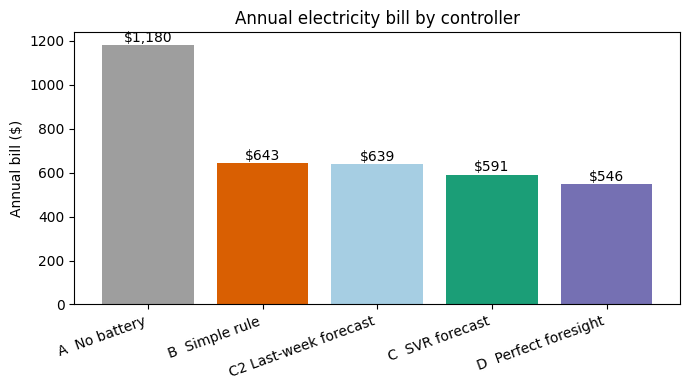

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
order = ["A", "B", "C2", "C", "D"]
colours = ["#9e9e9e", "#d95f02", "#a6cee3", "#1b9e77", "#7570b3"]
ax.bar([names[k] for k in order], [bills.loc[k, "total"] for k in order], color=colours)
for i, k in enumerate(order):
    ax.text(i, bills.loc[k, "total"] + 15, f"${bills.loc[k, 'total']:,.0f}", ha="center")
ax.set_ylabel("Annual bill ($)")
ax.set_title("Annual electricity bill by controller")
plt.xticks(rotation=20, ha="right")
fig.tight_layout()
fig.savefig(ROOT / "results" / "fig_bills_by_controller.png", dpi=150)
plt.show()

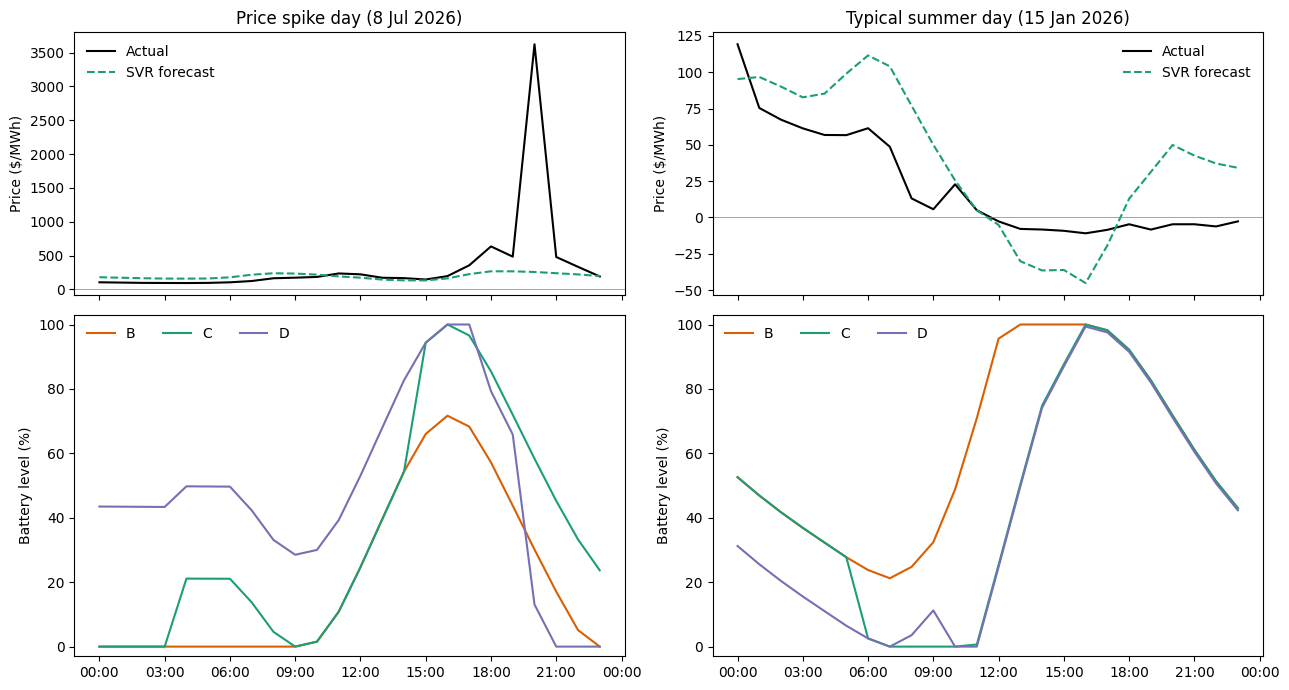

In [6]:
def sample_days(days, fname):
    cols = {"B": "#d95f02", "C": "#1b9e77", "D": "#7570b3"}
    fig, axes = plt.subplots(2, len(days), figsize=(6.5 * len(days), 7), sharex="col",
                             gridspec_kw={"height_ratios": [1, 1.3]})
    for j, (day, title) in enumerate(days):
        d = slice(day, day + " 23:59")
        ax = axes[0, j]
        ax.plot(fc.loc[d].index, fc.loc[d, "price_actual_mwh"], color="black", label="Actual")
        ax.plot(fc.loc[d].index, fc.loc[d, "price_forecast_mwh"], color="#1b9e77", ls="--", label="SVR forecast")
        ax.axhline(0, color="grey", lw=0.5)
        ax.set_ylabel("Price ($/MWh)"); ax.set_title(title); ax.legend(frameon=False)
        ax = axes[1, j]
        for n, c in cols.items():
            ax.plot(runs[n].loc[d].index, runs[n].loc[d, "soc"] * 100, color=c, label=n)
        ax.set_ylabel("Battery level (%)"); ax.set_ylim(-3, 103); ax.legend(frameon=False, ncol=3)
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    fig.tight_layout()
    fig.savefig(ROOT / "results" / fname, dpi=150)
    plt.show()

sample_days([("2026-07-08", "Price spike day (8 Jul 2026)"),
             ("2026-01-15", "Typical summer day (15 Jan 2026)")], "fig_sample_days.png")